# **Machine Learning Assignment 2**
BITS ID: **2026CT05153**

Programme: M.Tech AIML Course: Machine Learning

Assignment: Classification Model Development and Comparative Evaluation

In [51]:
!pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn

### Imports

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from ucimlrepo import fetch_ucirepo
import joblib
import os
import time

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)


# Store evaluation results and trained models
results = []
trained_models = {}

print("Machine learning libraries imported successfully!")
RANDOM_STATE = 42
print("Preprocessing libraries imported successfully!")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Libraries imported successfully!")


Machine learning libraries imported successfully!
Preprocessing libraries imported successfully!
Libraries imported successfully!


### Dataset

In [53]:

# Fetch Adult Census Income dataset from UCI
adult = fetch_ucirepo(id=2)

# Extract features and target
X = adult.data.features
y = adult.data.targets

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (48842, 15)

First five rows:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


### Display dataset information

In [54]:
print("Dataset Information:")
df.info()

print("\nDataset dimensions:")
print(df.shape)

print("\nStatistical summary:")
display(df.describe(include='all').T)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB

Dataset dimensions:
(48842, 15)

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,47879,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,47876,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### missing values

In [55]:
print("Actual missing values:")
print(df.isnull().sum())
print("\nQuestion marks in each column:")

for col in df.select_dtypes(include='object').columns:
    count = df[col].astype(str).str.strip().eq('?').sum()
    if count > 0:
        print(col, ":", count)


Actual missing values:
age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

Question marks in each column:
workclass : 1836
occupation : 1843
native-country : 583


### duplicate records

In [56]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No duplicate records found.")


Number of duplicate records: 29


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
2303,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
3917,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
4325,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
4767,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,<=50K
4881,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
4940,38,Private,207202,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,48,United-States,>50K
5104,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
5579,27,Private,255582,HS-grad,9,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40,United-States,<=50K
5805,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
5842,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala,<=50K


### Target variable distribution

Income distribution:
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

Income percentage:
income
<=50K     50.612178
<=50K.    25.459645
>50K      16.053806
>50K.      7.874370
Name: proportion, dtype: float64


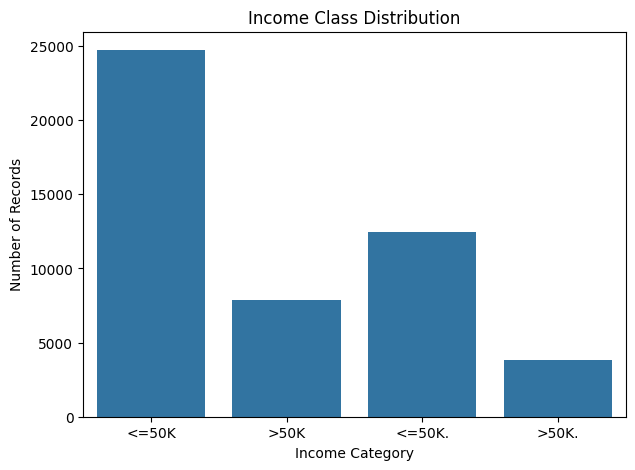

In [57]:
print("Income distribution:")
print(df['income'].value_counts())

print("\nIncome percentage:")
print(df['income'].value_counts(normalize=True) * 100)

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='income')

plt.title('Income Class Distribution')
plt.xlabel('Income Category')
plt.ylabel('Number of Records')

plt.show()


Corrected Income Distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

Corrected Income Percentages:
income
<=50K    76.071823
>50K     23.928177
Name: proportion, dtype: float64


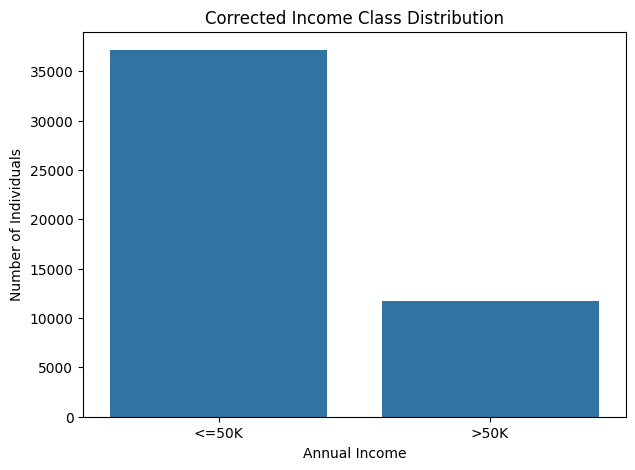

In [58]:
# Standardize income labels
df['income'] = (
    df['income']
    .astype(str)
    .str.strip()
    .str.rstrip('.')
)

# Check corrected distribution
print("Corrected Income Distribution:")
print(df['income'].value_counts())

print("\nCorrected Income Percentages:")
print(df['income'].value_counts(normalize=True) * 100)

# Plot corrected distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='income')

plt.title('Corrected Income Class Distribution')
plt.xlabel('Annual Income')
plt.ylabel('Number of Individuals')

plt.show()


### features

In [59]:
# Numerical features
numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Categorical features
categorical_features = df.select_dtypes(
    include=['object']
).columns.tolist()

# Remove target variable from feature lists
numerical_features = [
    col for col in numerical_features if col != 'income'
]

categorical_features = [
    col for col in categorical_features if col != 'income'
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal numerical features:", len(numerical_features))
print("Total categorical features:", len(categorical_features))


Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Total numerical features: 6
Total categorical features: 8


In [60]:
df_check = df.replace('?', np.nan)

print("Missing values per column:")
print(df_check.isnull().sum())

print("\nTotal missing cells:")
print(df_check.isnull().sum().sum())


Missing values per column:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64

Total missing cells:
6465


In [61]:
# Create a copy of the dataset
df_clean = df.copy()

# Remove extra whitespace from categorical columns
for col in df_clean.select_dtypes(include=['object', 'string']).columns:
    df_clean[col] = df_clean[col].str.strip()

# Standardize income labels
df_clean['income'] = df_clean['income'].str.rstrip('.')

# Replace question marks with NaN
df_clean = df_clean.replace('?', np.nan)

# Check duplicates after standardization
print("Records before cleaning:", len(df_clean))
print("Duplicate records:", df_clean.duplicated().sum())

# Remove duplicate records
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Records after cleaning:", len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())

print("\nRemaining missing values:")
print(df_clean.isnull().sum())


Records before cleaning: 48842
Duplicate records: 52
Records after cleaning: 48790
Remaining duplicates: 0

Remaining missing values:
age                  0
workclass         2795
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2805
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     856
income               0
dtype: int64


In [62]:
# Separate independent and dependent variables
X = df_clean.drop(columns=['income'])

# Encode target variable
y = df_clean['income'].map({
    '<=50K': 0,
    '>50K': 1
})

assert y.notna().all()

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nEncoded target distribution:")
print(y.value_counts())

print("\nTarget encoding completed successfully!")


Input features shape: (48790, 14)
Target variable shape: (48790,)

Encoded target distribution:
income
0    37109
1    11681
Name: count, dtype: int64

Target encoding completed successfully!


### Split dataset into training and testing sets

In [63]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nOriginal class distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nTraining class distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))


Training features shape: (39032, 14)
Testing features shape: (9758, 14)

Training target shape: (39032,)
Testing target shape: (9758,)

Original class distribution (%):
income
0    76.06
1    23.94
Name: proportion, dtype: float64

Training class distribution (%):
income
0    76.06
1    23.94
Name: proportion, dtype: float64

Testing class distribution (%):
income
0    76.06
1    23.94
Name: proportion, dtype: float64


In [64]:
# Identify feature types from training data
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing pipeline
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully!")


Numerical features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Preprocessing pipeline created successfully!


In [65]:
# Fit preprocessing ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data without fitting again
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values in processed training data:",
      np.isnan(X_train_processed).sum())

print("Missing values in processed testing data:",
      np.isnan(X_test_processed).sum())

print("\nPreprocessing completed successfully!")


Original training shape: (39032, 14)
Processed training shape: (39032, 105)

Original testing shape: (9758, 14)
Processed testing shape: (9758, 105)

Missing values in processed training data: 0
Missing values in processed testing data: 0

Preprocessing completed successfully!


## evaluate_model

In [66]:
def evaluate_model(model_name, model):

    start_time = time.time()

    # Train the model
    model.fit(X_train_processed, y_train)

    training_time = time.time() - start_time

    # Predict class labels
    y_pred = model.predict(X_test_processed)

    # Predict positive class probabilities
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Calculate evaluation metrics
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'MCC': matthews_corrcoef(y_test, y_pred)
    }

    # Store results
    results.append(metrics)
    trained_models[model_name] = model

    # Display results
    print("=" * 50)
    print("Model:", model_name)
    print("=" * 50)

    for metric, value in metrics.items():
        if metric != 'Model':
            print(f"{metric}: {value:.4f}")

    print(f"\nTraining time: {training_time:.2f} seconds")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=['<=50K', '>50K'],
        zero_division=0
    ))

    return metrics

print("Evaluation function created successfully!")


Evaluation function created successfully!


## Model 1: Logistic Regression

In [67]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

lr_results = evaluate_model(
    'Logistic Regression',
    lr_model
)


Model: Logistic Regression
Accuracy: 0.8520
AUC: 0.9081
Precision: 0.7304
Recall: 0.6053
F1: 0.6620
MCC: 0.5724

Training time: 2.90 seconds

Confusion Matrix:
[[6900  522]
 [ 922 1414]]

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      7422
        >50K       0.73      0.61      0.66      2336

    accuracy                           0.85      9758
   macro avg       0.81      0.77      0.78      9758
weighted avg       0.85      0.85      0.85      9758



## Model 2: Decision Tree Classifier

In [68]:
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=10,
    min_samples_split=10,
    random_state=RANDOM_STATE
)

dt_results = evaluate_model(
    'Decision Tree',
    dt_model
)


Model: Decision Tree
Accuracy: 0.8651
AUC: 0.9067
Precision: 0.7763
Recall: 0.6134
F1: 0.6853
MCC: 0.6077

Training time: 1.50 seconds

Confusion Matrix:
[[7009  413]
 [ 903 1433]]

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.91      7422
        >50K       0.78      0.61      0.69      2336

    accuracy                           0.87      9758
   macro avg       0.83      0.78      0.80      9758
weighted avg       0.86      0.87      0.86      9758



## Model 3: K-Nearest Neighbors

In [69]:
knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights='distance',
    metric='minkowski',
    p=2,
    n_jobs=-1
)

knn_results = evaluate_model(
    'K-Nearest Neighbors',
    knn_model
)


Model: K-Nearest Neighbors
Accuracy: 0.8366
AUC: 0.8764
Precision: 0.6747
Recall: 0.6134
F1: 0.6426
MCC: 0.5381

Training time: 0.03 seconds

Confusion Matrix:
[[6731  691]
 [ 903 1433]]

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.89      7422
        >50K       0.67      0.61      0.64      2336

    accuracy                           0.84      9758
   macro avg       0.78      0.76      0.77      9758
weighted avg       0.83      0.84      0.83      9758



## Model 4: Gaussian Naive Bayes

In [70]:
nb_model = GaussianNB(
    var_smoothing=1e-9
)

nb_results = evaluate_model(
    'Naive Bayes',
    nb_model
)


Model: Naive Bayes
Accuracy: 0.5990
AUC: 0.8174
Precision: 0.3672
Recall: 0.9336
F1: 0.5271
MCC: 0.3736

Training time: 0.14 seconds

Confusion Matrix:
[[3664 3758]
 [ 155 2181]]

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.96      0.49      0.65      7422
        >50K       0.37      0.93      0.53      2336

    accuracy                           0.60      9758
   macro avg       0.66      0.71      0.59      9758
weighted avg       0.82      0.60      0.62      9758



## Model 5: Random Forest Classifier

In [71]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_results = evaluate_model(
    'Random Forest',
    rf_model
)


Model: Random Forest
Accuracy: 0.8671
AUC: 0.9202
Precision: 0.7957
Recall: 0.5985
F1: 0.6831
MCC: 0.6109

Training time: 8.38 seconds

Confusion Matrix:
[[7063  359]
 [ 938 1398]]

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.92      7422
        >50K       0.80      0.60      0.68      2336

    accuracy                           0.87      9758
   macro avg       0.84      0.78      0.80      9758
weighted avg       0.86      0.87      0.86      9758



## Machine Learning Model Comparison

In [72]:
# Convert evaluation results into a DataFrame
results_df = pd.DataFrame(results)

# Avoid duplicate entries if a model cell was rerun
results_df = results_df.drop_duplicates(
    subset='Model',
    keep='last'
).reset_index(drop=True)

print("Machine Learning Model Comparison")
display(results_df.round(4))

# Save evaluation results
results_df.to_csv('model_comparison.csv', index=False)

print("Model comparison saved successfully!")


Machine Learning Model Comparison


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8520,0.9081,0.7304,0.6053,0.6620,0.5724
1,Decision Tree,0.8651,0.9067,0.7763,0.6134,0.6853,0.6077
2,K-Nearest Neighbors,0.8366,0.8764,0.6747,0.6134,0.6426,0.5381
3,Naive Bayes,0.5990,0.8174,0.3672,0.9336,0.5271,0.3736
4,Random Forest,0.8671,0.9202,0.7957,0.5985,0.6831,0.6109


Model comparison saved successfully!


## visualizations

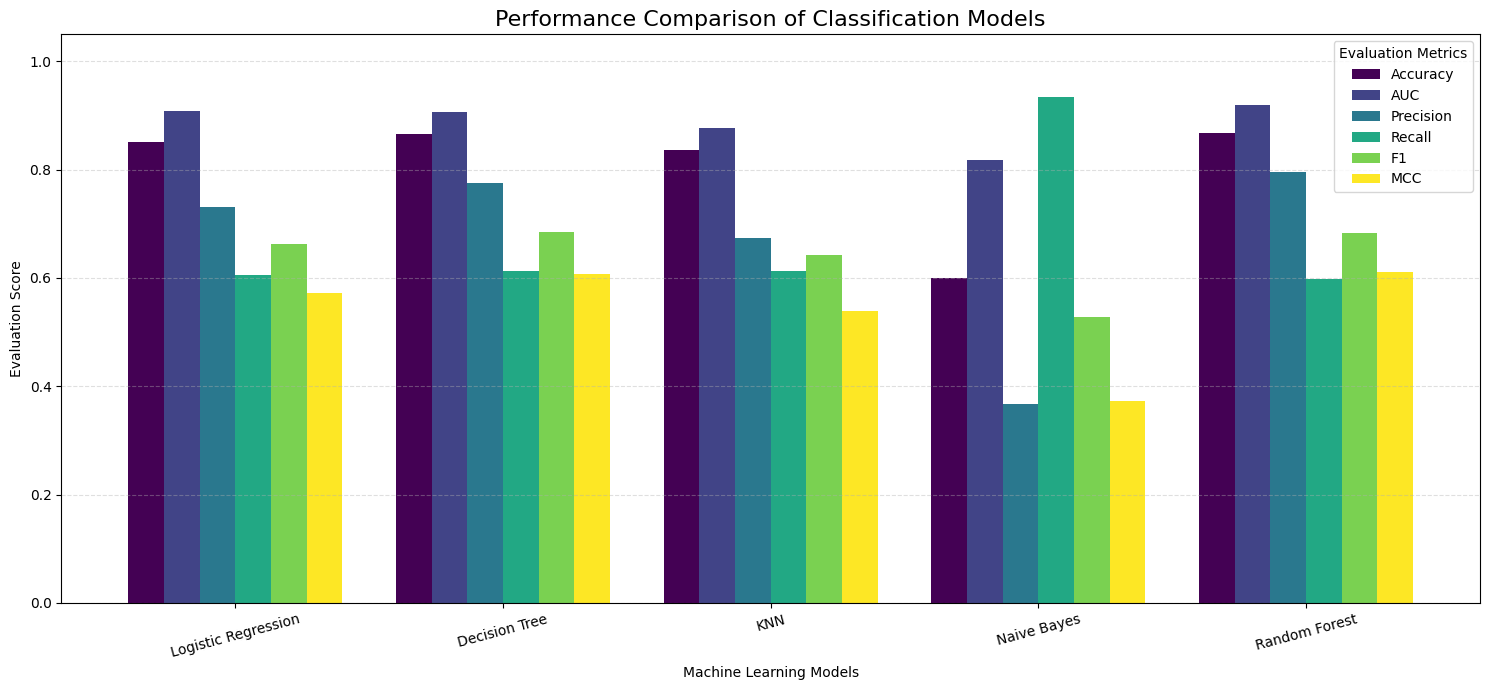

In [73]:
# Create a folder for visualizations
os.makedirs('visualizations', exist_ok=True)

# Evaluation metrics
metric_names = [
    'Accuracy', 'AUC', 'Precision',
    'Recall', 'F1', 'MCC'
]

# Short model names for visualization
plot_df = results_df.copy()

plot_df['Model'] = plot_df['Model'].replace({
    'Logistic Regression': 'Logistic Regression',
    'K-Nearest Neighbors': 'KNN'
})

# Grouped bar chart
ax = plot_df.set_index('Model')[metric_names].plot(
    kind='bar',
    figsize=(15, 7),
    width=0.8,
    colormap='viridis'
)

plt.title(
    'Performance Comparison of Classification Models',
    fontsize=16
)

plt.xlabel('Machine Learning Models')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig(
    'visualizations/model_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## heatmap

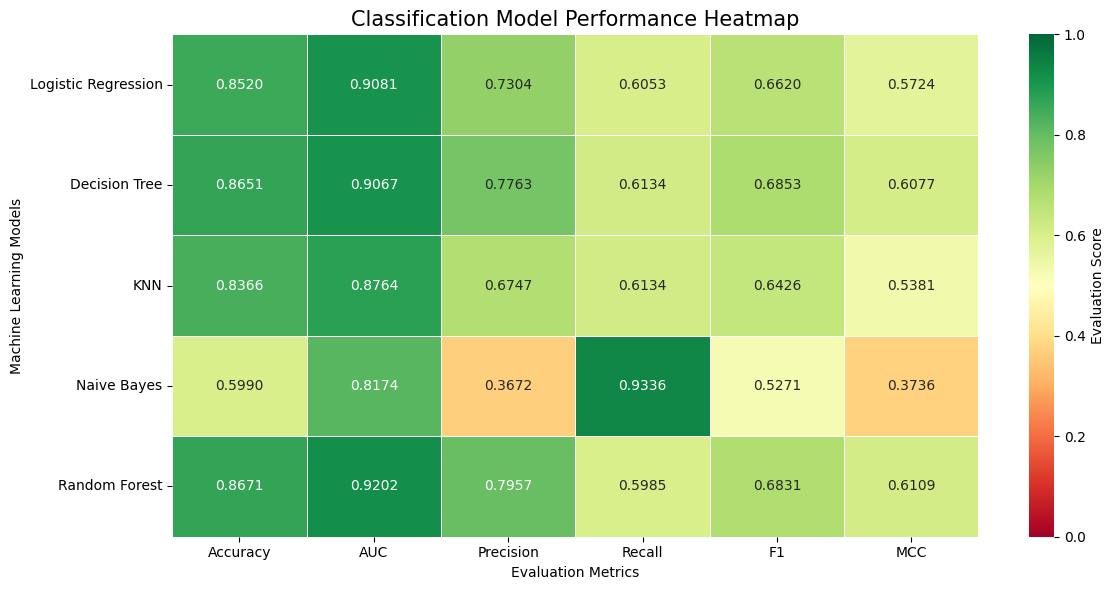

In [74]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    plot_df.set_index('Model')[metric_names],
    annot=True,
    fmt='.4f',
    cmap='RdYlGn',
    linewidths=0.5,
    vmin=0,
    vmax=1,
    cbar_kws={'label': 'Evaluation Score'}
)

plt.title('Classification Model Performance Heatmap',
          fontsize=15)

plt.xlabel('Evaluation Metrics')
plt.ylabel('Machine Learning Models')
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    'visualizations/performance_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## confusion matrices for all five models

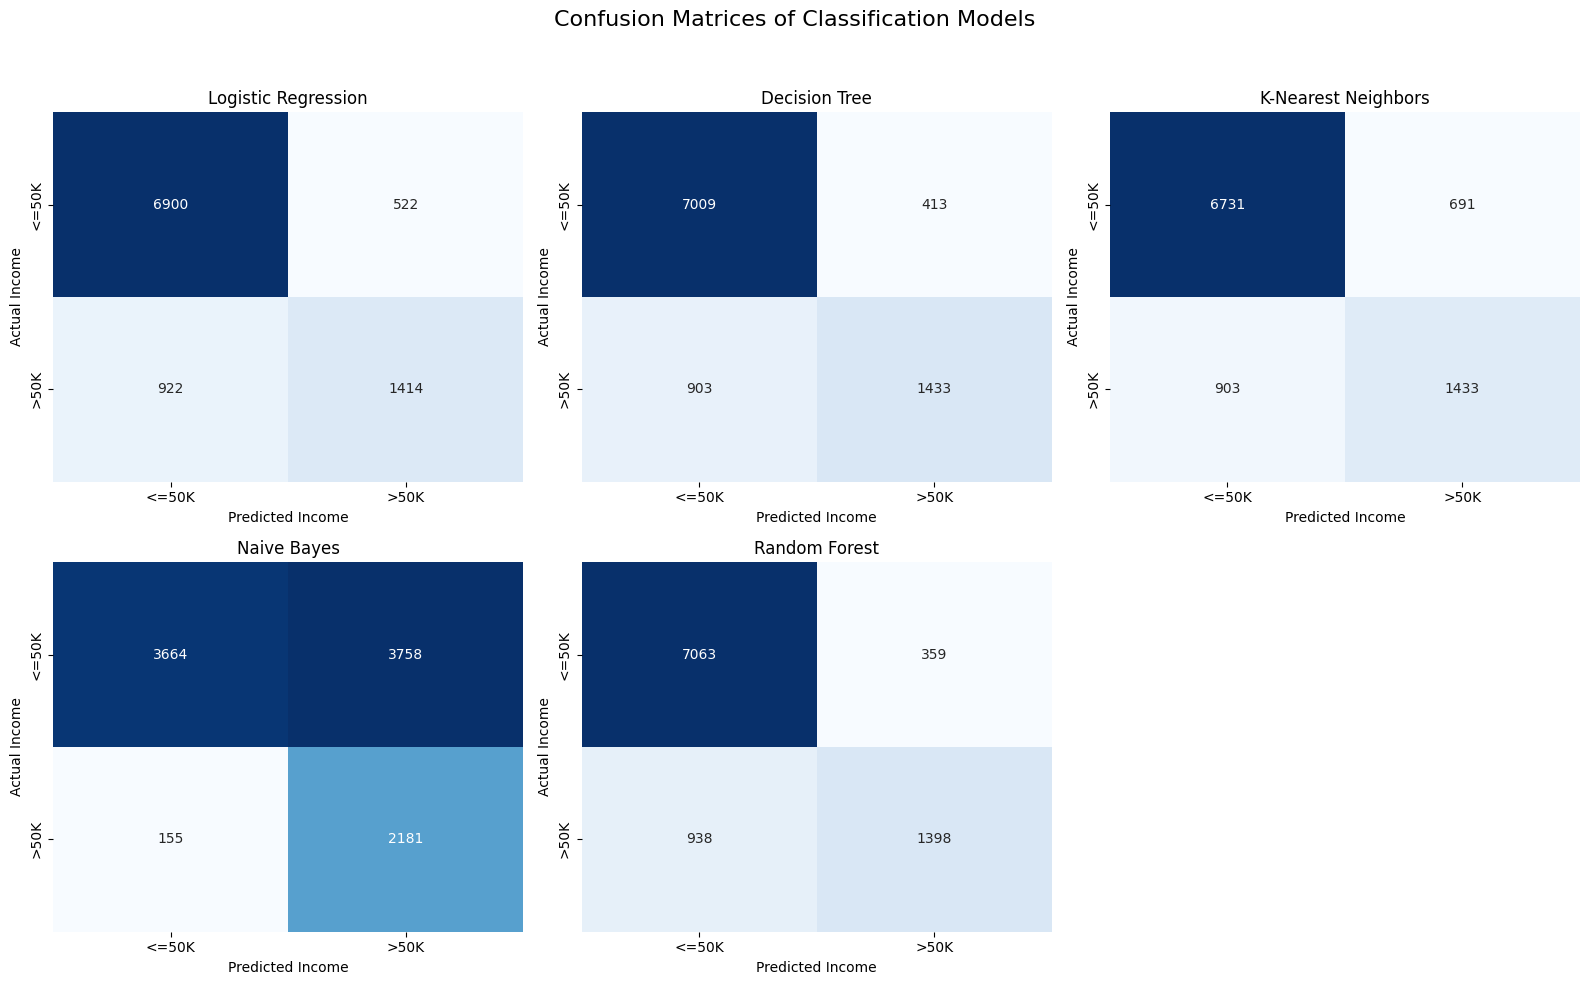

In [75]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=axes[i],
        xticklabels=['<=50K', '>50K'],
        yticklabels=['<=50K', '>50K']
    )

    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted Income')
    axes[i].set_ylabel('Actual Income')

# Remove unused sixth subplot
fig.delaxes(axes[5])

plt.suptitle(
    'Confusion Matrices of Classification Models',
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    'visualizations/confusion_matrices.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## ROC Curve

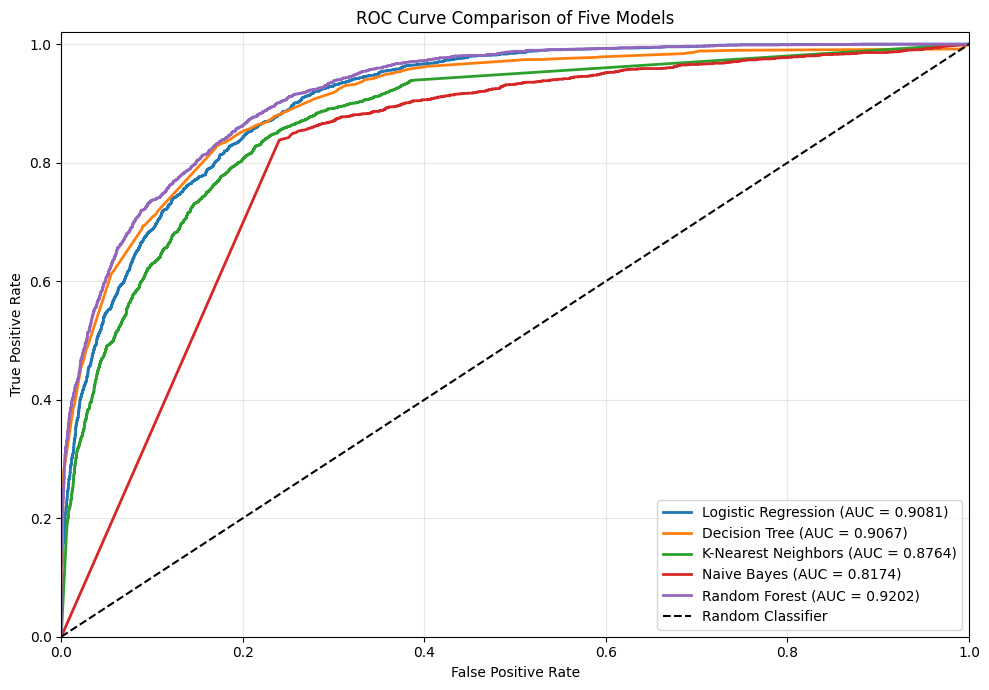

In [76]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    y_prob = model.predict_proba(
        X_test_processed
    )[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {roc_auc:.4f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Five Models')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.tight_layout()

plt.savefig(
    'visualizations/roc_curves.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## Individual Evaluation Metric Comparison

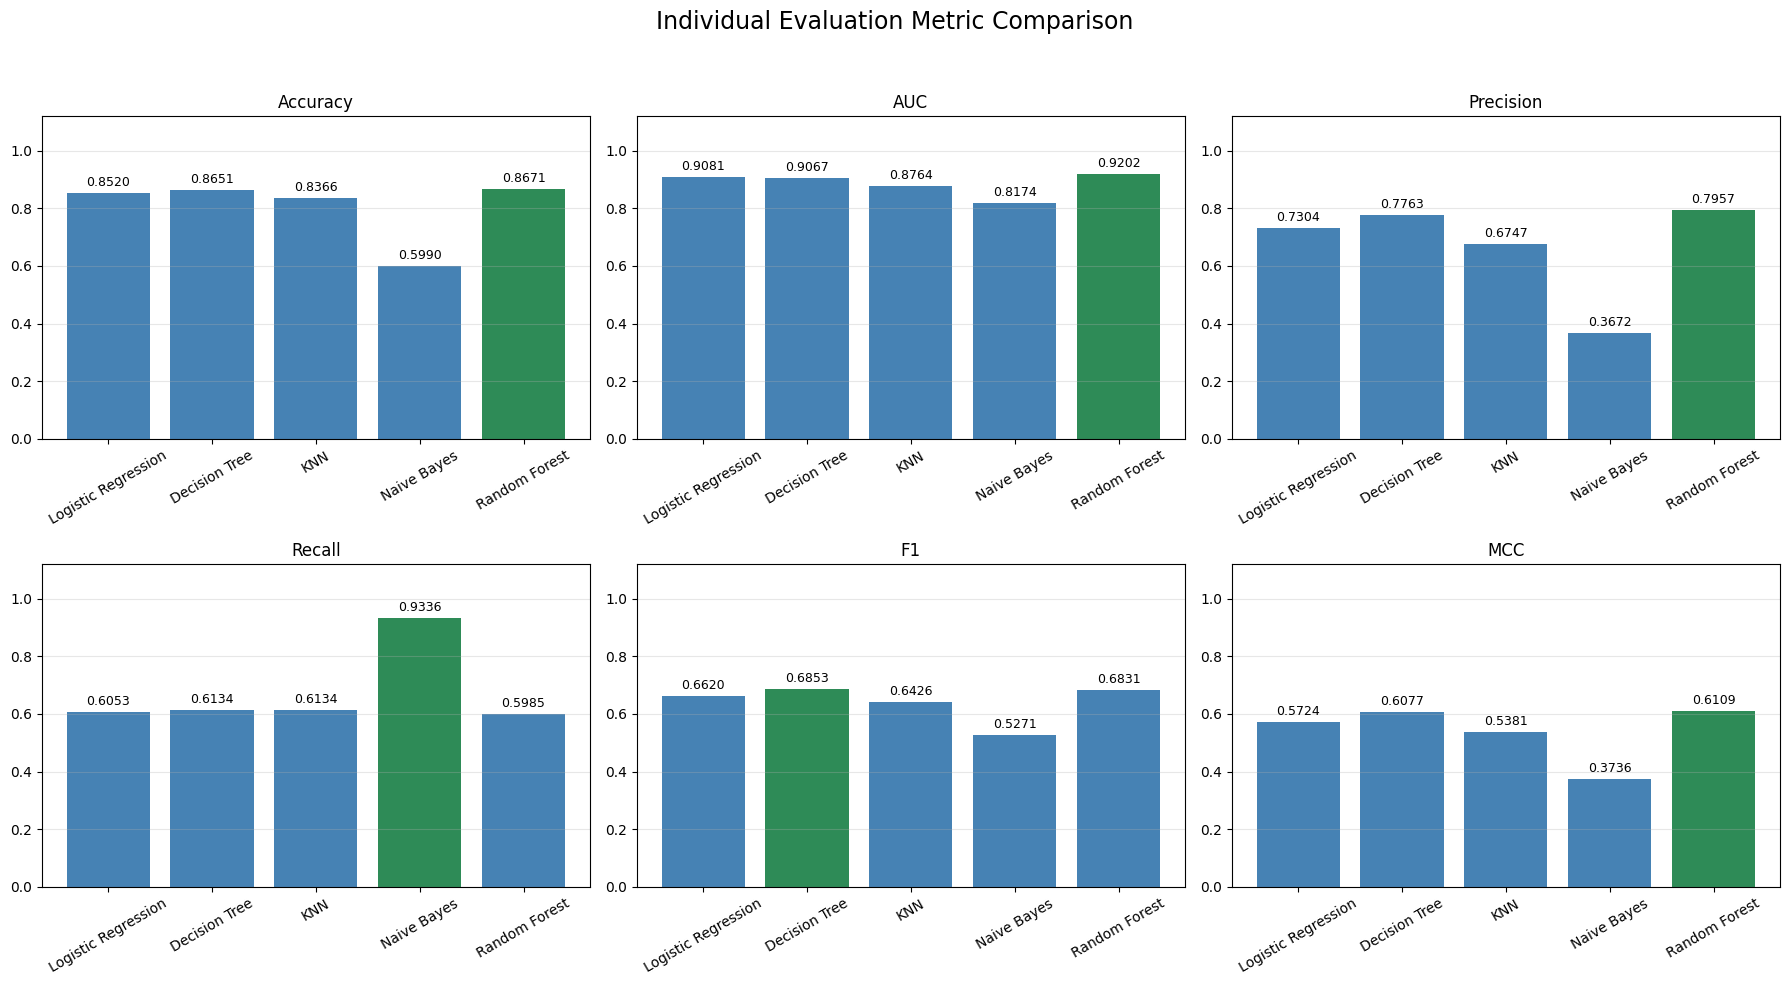

In [77]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, metric in enumerate(metric_names):

    values = plot_df[metric]

    best_index = values.idxmax()

    colors = [
        'seagreen' if idx == best_index
        else 'steelblue'
        for idx in values.index
    ]

    bars = axes[i].bar(
        plot_df['Model'],
        values,
        color=colors
    )

    axes[i].set_title(metric)
    axes[i].set_ylim(0, 1.12)
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].grid(axis='y', alpha=0.3)

    axes[i].bar_label(
        bars,
        fmt='%.4f',
        padding=3,
        fontsize=9
    )

plt.suptitle(
    'Individual Evaluation Metric Comparison',
    fontsize=17
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    'visualizations/individual_metrics.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [78]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(
    strategy='most_frequent'
)

baseline_model.fit(X_train_processed, y_train)

baseline_pred = baseline_model.predict(
    X_test_processed
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")

print("\nAccuracy improvement over baseline:")

for _, row in results_df.iterrows():

    improvement = (
        row['Accuracy'] - baseline_accuracy
    ) * 100

    print(
        f"{row['Model']}: "
        f"{improvement:+.2f} percentage points"
    )


Baseline Accuracy: 0.7606

Accuracy improvement over baseline:
Logistic Regression: +9.14 percentage points
Decision Tree: +10.45 percentage points
K-Nearest Neighbors: +7.60 percentage points
Naive Bayes: -16.16 percentage points
Random Forest: +10.65 percentage points


In [79]:
import os
import shutil
from pathlib import Path

# Project directory
project_dir = Path('/content/Adult_Income_Classification')

# Create required folders
(project_dir / 'model').mkdir(
    parents=True, exist_ok=True
)

(project_dir / 'visualizations').mkdir(
    parents=True, exist_ok=True
)

print("Project folders created successfully!")
print("Project location:", project_dir)


Project folders created successfully!
Project location: /content/Adult_Income_Classification


In [80]:
# Combine test features and target
test_data = X_test.copy()

test_data['income'] = y_test

# Save test data
test_data.to_csv(
    project_dir / 'test_data.csv',
    index=False
)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

display(test_data.head())


Test dataset saved successfully!
Test dataset shape: (9758, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
30283,40,Private,126868,HS-grad,9,Divorced,Machine-op-inspct,Not-in-family,Black,Male,0,0,40,United-States,0
26714,84,Private,188328,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,0,16,United-States,0
18001,71,NaN,128529,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,0,20,United-States,0
20162,25,Private,71351,1st-4th,2,Never-married,Other-service,Other-relative,White,Male,0,0,25,El-Salvador,0
10476,39,Private,204501,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,United-States,1


In [81]:
from sklearn.pipeline import Pipeline
import joblib

# Model filenames
model_filenames = {
    'Logistic Regression': 'logistic_regression',
    'Decision Tree': 'decision_tree',
    'K-Nearest Neighbors': 'knn',
    'Naive Bayes': 'naive_bayes',
    'Random Forest': 'random_forest'
}

# Save complete fitted pipelines
for name, model in trained_models.items():

    complete_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    file_path = (
        project_dir / 'model' /
        f'{model_filenames[name]}.joblib'
    )

    joblib.dump(
        complete_pipeline,
        file_path,
        compress=3
    )

    print(f"Saved: {file_path.name}")

print("\nAll five model pipelines saved!")


Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: random_forest.joblib

All five model pipelines saved!


In [82]:
# Verify all saved models
for name, model in trained_models.items():

    file_path = (
        project_dir / 'model' /
        f'{model_filenames[name]}.joblib'
    )

    loaded_pipeline = joblib.load(file_path)

    # Predict using raw test features
    loaded_predictions = loaded_pipeline.predict(
        X_test
    )

    # Original model predictions
    original_predictions = model.predict(
        X_test_processed
    )

    # Compare predictions
    identical = np.array_equal(
        loaded_predictions,
        original_predictions
    )

    accuracy = accuracy_score(
        y_test,
        loaded_predictions
    )

    print(f"\nModel: {name}")
    print(f"Predictions identical: {identical}")
    print(f"Accuracy: {accuracy:.4f}")

    assert identical

print("\nAll saved models verified successfully!")



Model: Logistic Regression
Predictions identical: True
Accuracy: 0.8520

Model: Decision Tree
Predictions identical: True
Accuracy: 0.8651

Model: K-Nearest Neighbors
Predictions identical: True
Accuracy: 0.8366

Model: Naive Bayes
Predictions identical: True
Accuracy: 0.5990

Model: Random Forest
Predictions identical: True
Accuracy: 0.8671

All saved models verified successfully!


Copied: model_comparison.png
Copied: performance_heatmap.png
Copied: confusion_matrices.png
Copied: roc_curves.png
Copied: individual_metrics.png


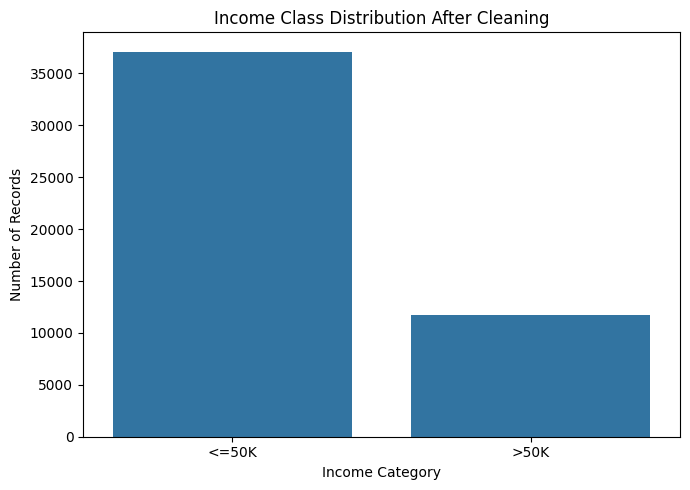

Results and visualizations saved!


In [83]:
# Save model comparison table
results_df.to_csv(
    project_dir / 'model_comparison.csv',
    index=False
)

# Copy all generated graphs
for filename in os.listdir('visualizations'):

    source = Path('visualizations') / filename

    destination = (
        project_dir / 'visualizations' / filename
    )

    if source.is_file():
        shutil.copy2(source, destination)
        print("Copied:", filename)

# Save corrected income distribution graph
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x='income',
    order=['<=50K', '>50K']
)

plt.title('Income Class Distribution After Cleaning')
plt.xlabel('Income Category')
plt.ylabel('Number of Records')
plt.tight_layout()

plt.savefig(
    project_dir / 'visualizations' /
    'income_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Results and visualizations saved!")


In [84]:
from importlib.metadata import version

packages = [
    'numpy',
    'pandas',
    'scikit-learn',
    'matplotlib',
    'seaborn',
    'ucimlrepo',
    'joblib'
]

requirements = [
    f"{package}=={version(package)}"
    for package in packages
]

requirements_path = project_dir / 'requirements.txt'

requirements_path.write_text(
    '\n'.join(requirements) + '\n'
)

print("requirements.txt created successfully!\n")
print(requirements_path.read_text())


requirements.txt created successfully!

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
ucimlrepo==0.0.7
joblib==1.6.0



In [85]:
# Display project files and sizes
print("PROJECT FOLDER STRUCTURE")
print("=" * 60)

for path in sorted(project_dir.rglob('*')):

    if path.is_file():

        relative_path = path.relative_to(
            project_dir
        )

        size_mb = path.stat().st_size / (
            1024 * 1024
        )

        print(f"{relative_path} ({size_mb:.2f} MB)")

print("=" * 60)

total_size = sum(
    p.stat().st_size
    for p in project_dir.rglob('*')
    if p.is_file()
)

print(
    f"Total project size: "
    f"{total_size / (1024 * 1024):.2f} MB"
)


PROJECT FOLDER STRUCTURE
model/decision_tree.joblib (0.02 MB)
model/knn.joblib (1.67 MB)
model/logistic_regression.joblib (0.00 MB)
model/naive_bayes.joblib (0.01 MB)
model/random_forest.joblib (3.61 MB)
model_comparison.csv (0.00 MB)
requirements.txt (0.00 MB)
test_data.csv (0.97 MB)
visualizations/confusion_matrices.png (0.25 MB)
visualizations/income_distribution.png (0.08 MB)
visualizations/individual_metrics.png (0.40 MB)
visualizations/model_comparison.png (0.21 MB)
visualizations/performance_heatmap.png (0.27 MB)
visualizations/roc_curves.png (0.34 MB)
Total project size: 7.82 MB
